# Projet Recherche Innovation

In [1]:
import numpy as np
import scipy
import numba
import matplotlib.pyplot as plt

print("Environnement configuré avec succès !")

Environnement configuré avec succès !


In [36]:
T_test = 1.0 #1an de maturité
n_test = 365 #par jour
t = np.linspace(0, T_test, n_test + 1)

# Brownian Motion

In [3]:
def Brownian_path(T, n): 
    dt = T/n
    W = np.zeros(n+1)
    for i in range(1,n+1): 
        W[i]=W[i-1]+np.random.normal(0,np.sqrt(dt)) 
    return W

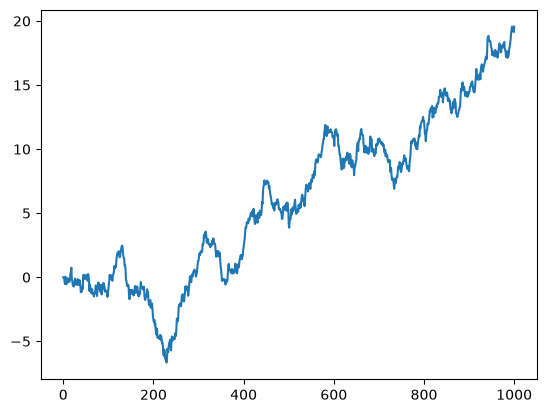

In [5]:
path=Brownian_path(T_test,n_test)
plt.plot(path)
plt.show()

## Exemple Black-scholes

1. Actif sans risque

In [19]:
# parametres de simulation
r = 0.05 

# Actif sans risque
S_zero = 100
def risk_free_asset(T, n, r):
    dt = T/n
    S = np.zeros(n+1)
    S[0] = S_zero
    for i in range(1,n+1):
        S[i] = S[0] * np.exp(r * i *  dt)
    return S


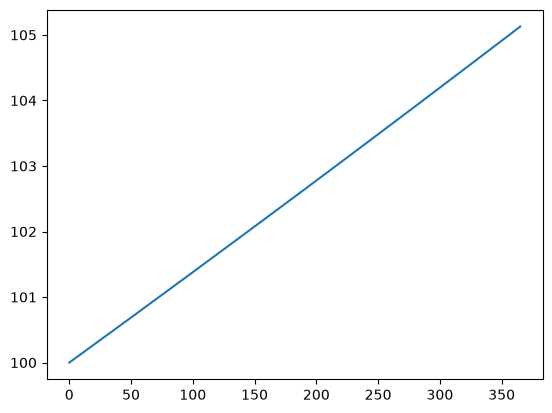

In [20]:
path=risk_free_asset(T_test,n_test,r)
plt.plot(path)
plt.show()

2. Actif risqué

In [27]:
# parametres de simulation
volatilite = 0.2
tendance = 0.08

def prix_actif_risque(T, n, tendance, taux_interet, sigma):
    dt = T/n
    S = np.zeros(n+1)
    S_tilde = np.zeros(n+1)
    S[0] = S_zero
    S_tilde[0] = S_zero
    brownian = Brownian_path(T,n) 
    for i in range(1,n+1):
        S[i] = S[0] * np.exp((tendance - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    for i in range(1,n+1):
        S_tilde[i] = S_tilde[0] * np.exp((tendance - taux_interet - 0.5 * sigma**2) * i * dt + sigma * brownian[i])
    return S,S_tilde

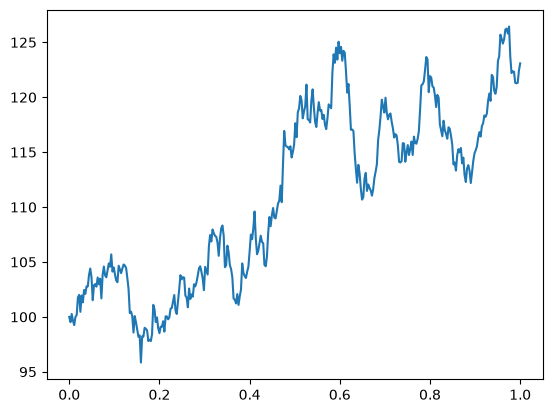

In [41]:
path_risque, path_risque_actualise=prix_actif_risque(T_test,n_test,tendance,r,volatilite)
plt.plot(t,path_risque)
plt.show()

3. Actif risqué actualisé

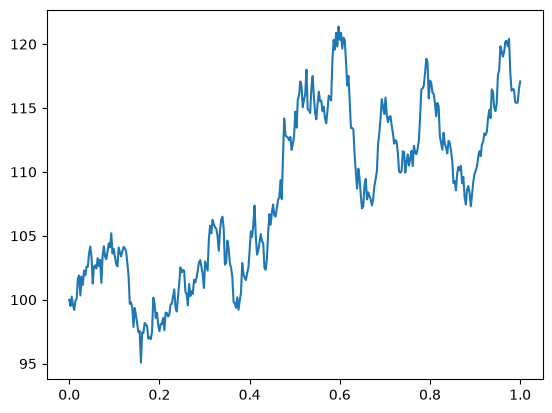

In [43]:
plt.plot(t, path_risque_actualise)
plt.show()

## 4. Simulation

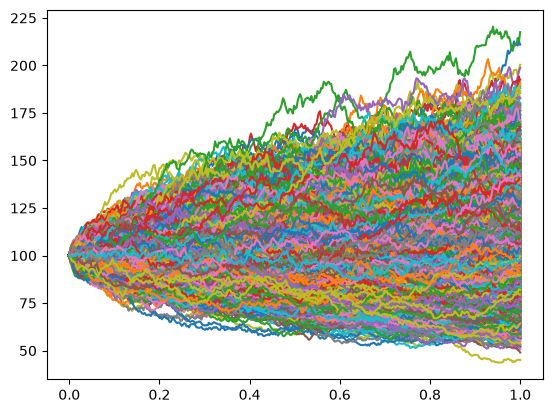

In [44]:
for i in range(10000):
    S,S_act = prix_actif_risque(T_test,n_test,tendance,r,volatilite)
    plt.plot(t,S_act)
plt.show()